### Sandbox Exercise 2: The Two-Site "Stiff" System (Advanced)

Background: Let's replicate the exact problem that causes differential equation solvers to crash when modeling cancer resistance networks. Consider a compound $B$ that has two independent proton binding sites ($K_{a_1}$ and $K_{a_2}$). It can exist as $B^{2-}$, $HB^{-}$, or $H_{2}B$


Your Exercise Task:

Write down the complete 3-term Binding Polynomial $P_{B}$ for this system using the macro pool definition:
$\sum{[B]}=[B^{2-}]+[HB^{-}]+[H_{2}B]$
Express your final polynomial strictly in terms of $[H^+]$, $K_{a_1}$, and $K_{a_2}$, choosing the completely unprotonated species $B^{2-}$ as your foundational baseline reference.

Note: $\text{HB}^-$ exists in two forms depending on which binding cite is occupied, which we represent as: $[\text{HB}_\unicode{x2460}^-], [HB_\unicode{x2461}^-]$


We will use the Bionetgen Language to illustrate the solution at a micro level. In Bionetgen, the two protonation reactions can be represented and visualized as:

### Reactions

##### Rule 1:Protonation of Site 1 (Driven by background $\text{H}^+$ ions pool)
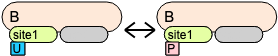

BNGL code: ```B(site1~U) <-> B(site1~P) k_on1*H_ions, k_off1```

##### Rule 2: Protonation of Site 2 (Independent of Site 1)
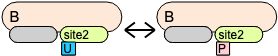

BNGL code: ```B(site2~U) ↔ B(site2~P) k_on2*H_ions, k_off2```

In [2]:
import bionetgen
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import tellurium as te

from scipy.integrate import solve_ivp

In [3]:
# 1. Run the rule-based simulation file
result = bionetgen.run("two_site_stiff.bngl")

In [4]:
# 2. Extract the time-course data matrix from the simulation
r = result[0]

In [5]:
r.dtype.names

('time',
 'Total_B',
 'Active_Bare_Ion',
 'First_Protonated',
 'Second_Protonated',
 'Fully_Protonated')

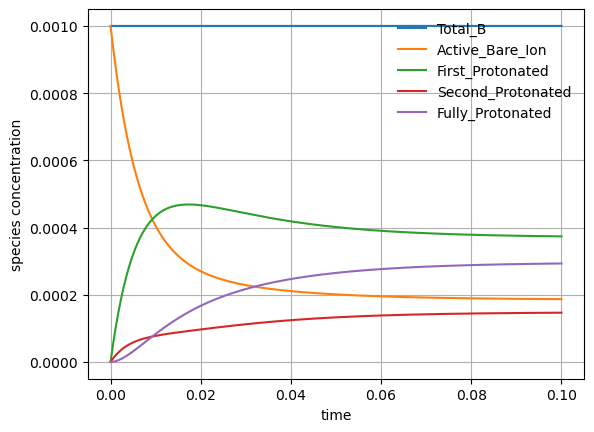

In [6]:
for name in r.dtype.names:
    if name != "time":
        plt.plot(r['time'], r[name], label=name)
plt.xlabel("time")
plt.ylabel("species concentration")
plt.grid()
_ = plt.legend(frameon=False)

$[\text{HB}_\boxed{1}^-]$

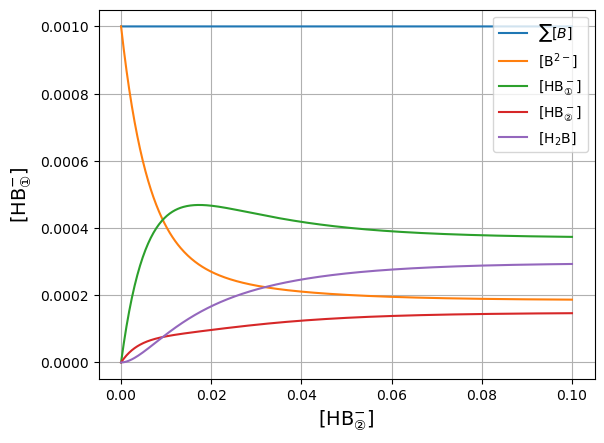

In [7]:
plt.plot(r['time'], r['Total_B'], label=r"$\sum{[B]}$")
plt.plot(r['time'], r['Active_Bare_Ion'], label=r"$[\mathrm{B}^{2-}]$")
plt.plot(r['time'], r['First_Protonated'], label=r"$[\mathrm{HB}_{" + chr(0x2460) + r"}^-]$")
plt.plot(r['time'], r['Second_Protonated'], label=r"$[\mathrm{HB}_{" + chr(0x2461) + r"}^-]$")
plt.plot(r['time'], r['Fully_Protonated'], label=r"$[\mathrm{H_2 B}]$")
plt.ylabel(r"$[\mathrm{HB}_{①}^{-}]$", fontsize=14)
plt.xlabel(r"$[\mathrm{HB}_{" + chr(0x2461) + r"}^{-}]$", fontsize=14)
plt.grid()
plt.legend()
plt.show()

In [10]:
B_tot = r['Total_B'][-1]
B = r['Active_Bare_Ion'][-1]
HB_1 = r['First_Protonated'][-1]
HB_2 = r['Second_Protonated'][-1]
H2B = r['Fully_Protonated'][-1]

In [11]:
model = bionetgen.bngmodel("two_site_stiff.bngl")

In [19]:
print(model)

begin model

begin parameters
  B_total 0.001
  H_ions 1e-06
  k_on1 100000000.0
  k_on2 20000000.0
  k_off1 50.0
  k_off2 25.0
  _rateLaw1 k_on1*H_ions
  _rateLaw2 k_on2*H_ions
end parameters

begin molecule types
  B(site1~U~P,site2~U~P)
end molecule types

begin species
  B(site1~U,site2~U) B_total
end species

begin observables
  Molecules Total_B B()
  Molecules Active_Bare_Ion B(site1~U,site2~U)
  Molecules First_Protonated B(site1~P,site2~U)
  Molecules Second_Protonated B(site1~U,site2~P)
  Molecules Fully_Protonated B(site1~P,site2~P)
end observables

begin reaction rules
  _R1: B(site1~U) <-> B(site1~P) _rateLaw1,k_off1 
  _R2: B(site2~U) <-> B(site2~P) _rateLaw2,k_off2 
end reaction rules

end model

generate_network({overwrite=>1})
writeSBML()
simulate({method=>"ode",t_start=>0,t_end=>0.1,n_steps=>500})


In [18]:
k_on1 = float(model.parameters['k_on1'].value)
k_off1 = float(model.parameters['k_off1'].value)
k_on2 = float(model.parameters['k_on2'].value)
k_off2 = float(model.parameters['k_off2'].value)
Ka1 = k_off1/k_on1
Ka2 = k_off2/k_on2

In [21]:
H = float(model.parameters['H_ions'].value)
H

1e-06

In [27]:
P = 1 + (1/Ka1 + 1/Ka2)*H + (1/(Ka1*Ka2))*H**2 
print(f"{P:4f}")

5.400000


In [25]:
print(f"{B_tot:.4f}")

0.0010


In [26]:
print(f"{B*P:.4f}")

0.0010
